# Oral Diseases Image Classification

**Objective:** Build, compare, and deploy an AI system that classifies oral disease images into six categories.

**Pipeline:**
1. Load and balance the dataset
2. Split into train / validation / test
3. Build a custom CNN and three pretrained models
4. Compare the models
5. Tune the best model and fine-tune it
6. Evaluate and analyze errors
7. Save the model for deployment (Streamlit)

**Dataset:** [Oral Diseases on Kaggle](https://www.kaggle.com/datasets/salmansajid05/oral-diseases)

## 1. Imports and Setup
Import the libraries and fix the random seed (`42`) so the results are reproducible.

In [ ]:
import os, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

## 2. Collecting the Data
The dataset has six classes. Hypodontia has the fewest images (1,251), so **1,250 images are sampled from every class** to keep the data balanced (6 × 1,250 = 7,500 images).

**Note on Caries:** its folder contains 219 original images and 2,382 augmented copies. Only the augmented folder is used so the class size matches the others. This is a limitation: copies of the same image may land in different splits (see the Limitations section at the end).

The YOLO-annotated folder is ignored because it is an object detection dataset, not a classification one.

In [2]:
base = "/kaggle/input/datasets/salmansajid05/oral-diseases"

class_folders = {
    "Calculus": f"{base}/Calculus/Calculus",
    "Gingivitis": f"{base}/Gingivitis",
    "Mouth_Ulcer": f"{base}/Mouth Ulcer",
    "Tooth_Discoloration": f"{base}/Tooth Discoloration",
    "Hypodontia": f"{base}/hypodontia",
    "Caries": f"{base}/Data caries/Data caries/caries augmented data set/preview",
}

PER_CLASS = 1250
all_paths, all_labels = [], []

In [3]:
for idx, (name, folder) in enumerate(class_folders.items()):
    paths = [
        os.path.join(root, f) 
        for root, _, files in os.walk(folder) 
        for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    random.shuffle(paths)
    selected = paths[:PER_CLASS]
    
    all_paths.extend(selected)
    all_labels.extend([idx] * len(selected))
    print(f"{name}: {len(selected)}")

print(f"Total: {len(all_paths)}")

Calculus: 1250
Gingivitis: 1250
Mouth_Ulcer: 1250
Tooth_Discoloration: 1250
Hypodontia: 1250
Caries: 1250
Total: 7500


## 3. Train / Validation / Test Split
The data is split **70% / 15% / 15%** with `stratify`, so every class keeps the same proportion in each set.

- **Train:** fit the models
- **Validation:** early stopping and hyperparameter selection
- **Test:** final evaluation only (never used for choosing settings)

In [4]:
train_p, temp_p, train_l, temp_l = train_test_split(
    all_paths, all_labels, test_size=0.30, stratify=all_labels, random_state=SEED)
val_p, test_p, val_l, test_l = train_test_split(
    temp_p, temp_l, test_size=0.50, stratify=temp_l, random_state=SEED)

print("Train:", len(train_p), "Val:", len(val_p), "Test:", len(test_p))

Train: 5250 Val: 1125 Test: 1125


## 4. Data Pipeline
Each image is read, converted to RGB, and resized to **224 × 224**. Batches are prefetched so the GPU is not left waiting. Only the training set is shuffled.

In [5]:
IMG = 224
AUTOTUNE = tf.data.AUTOTUNE

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    return img, label

def make_ds(paths, labels, batch=32, train=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if train:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)
    return ds

val_ds  = make_ds(val_p, val_l)
test_ds = make_ds(test_p, test_l)

I0000 00:00:1792982448.916307    1570 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792982448.918522    1570 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## 5. Sample Images
A quick visual check that the images are loaded correctly and the labels match the content.

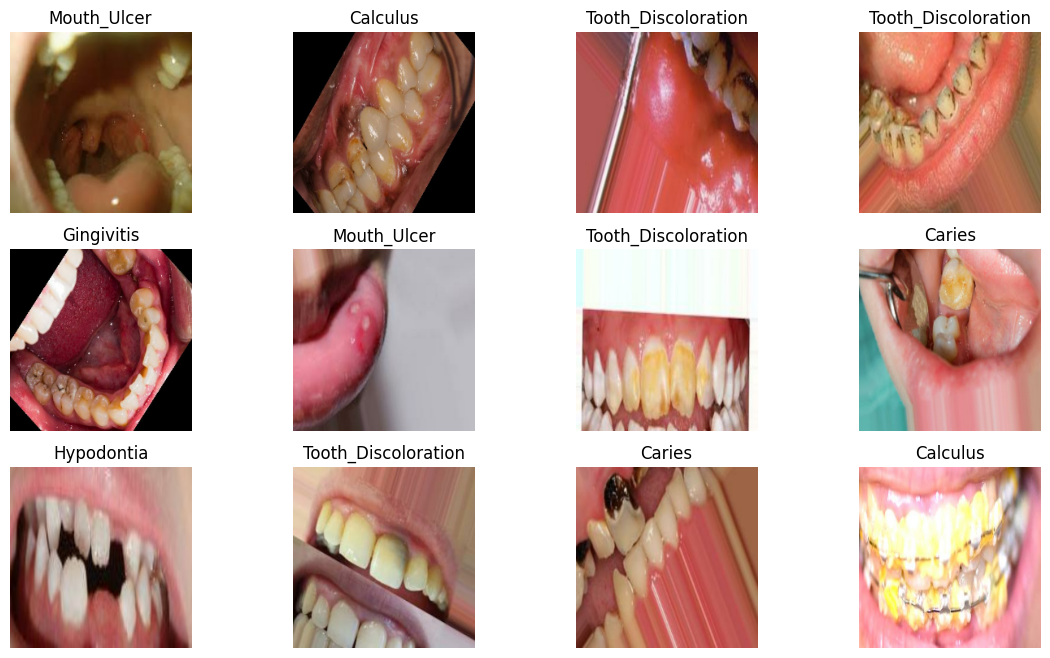

In [6]:
class_names = ["Calculus", "Gingivitis", "Mouth_Ulcer", "Tooth_Discoloration", "Hypodontia", "Caries"]
ds = make_ds(train_p, train_l, batch=12, train=True)
imgs, labs = next(iter(ds))
plt.figure(figsize=(14, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(imgs[i].numpy().astype("uint8"))
    plt.title(class_names[labs[i]])
    plt.axis("off")
plt.show()

## 6. Building the Models

**Data augmentation** (training only): random horizontal flip, rotation (±10%), and zoom (±10%).

**Custom CNN:** four blocks of `Conv2D + MaxPooling` (32, 64, 128, 256 filters), followed by global average pooling, a dense layer with dropout, and a softmax output.

**Pretrained models (Transfer Learning):** MobileNetV2, ResNet50, and EfficientNetB0, pretrained on ImageNet. The base is **frozen** and only a new classification head is trained (`GlobalAveragePooling2D → Dropout → Dense(6, softmax)`).

In [7]:
NUM_CLASSES = len(class_names)

aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [8]:
pretrained = {
    "MobileNetV2":    (keras.applications.MobileNetV2,    keras.applications.mobilenet_v2.preprocess_input),
    "ResNet50":       (keras.applications.ResNet50,        keras.applications.resnet50.preprocess_input),
    "EfficientNetB0": (keras.applications.EfficientNetB0, keras.applications.efficientnet.preprocess_input),
}

In [9]:
def build_custom_cnn(lr=1e-3, dropout=0.4):
    inp = keras.Input((IMG, IMG, 3))
    x = layers.Rescaling(1 / 255)(aug(inp))
    
    for f in [32, 64, 128, 256]:
        x = layers.MaxPooling2D()(layers.Conv2D(f, 3, padding="same", activation="relu")(x))
        
    out = layers.Dense(NUM_CLASSES, activation="softmax")(
        layers.Dropout(dropout)(layers.Dense(128, activation="relu")(layers.GlobalAveragePooling2D()(x)))
    )
    
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

In [10]:
def build_pretrained(name, lr=1e-3, dropout=0.3):
    base_cls, prep = pretrained[name]
    base_model = base_cls(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
    base_model.trainable = False
    
    inp = keras.Input((IMG, IMG, 3))
    x = base_model(prep(aug(inp)), training=False)
    
    out = layers.Dense(NUM_CLASSES, activation="softmax")(
        layers.Dropout(dropout)(layers.GlobalAveragePooling2D()(x))
    )
    
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def build_model(name, lr=1e-3, dropout=0.3):
    return build_custom_cnn(lr, dropout) if name == "Custom_CNN" else build_pretrained(name, lr, dropout)

## 7. Training and Evaluation Functions
- `train_model`: trains a model with **Early Stopping** (monitors `val_accuracy`, patience 3, restores the best weights).
- `evaluate_model`: returns accuracy, macro F1, and predictions for any dataset (test by default).

In [11]:
def train_model(name, lr=1e-3, batch=32, dropout=0.3, epochs=10):
    train_ds = make_ds(train_p, train_l, batch=batch, train=True)
    model = build_model(name, lr, dropout)
    stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[stop], verbose=1)
    return model, history

def evaluate_model(model, ds=None, labels=None):
    ds = test_ds if ds is None else ds
    labels = test_l if labels is None else labels
    y_true = np.array(labels)
    y_pred = np.argmax(model.predict(ds, verbose=0), axis=1)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    return acc, f1, y_pred

## 8. Training the Four Models
All four models are trained with the **same data and settings** (`lr = 1e-3`, `batch = 32`, up to 10 epochs) so the comparison is fair, then evaluated on the test set.

In [12]:
results, trained, histories = [], {}, {}

for name in ["Custom_CNN", "MobileNetV2", "ResNet50", "EfficientNetB0"]:
    print(f"{'='*20} {name} {'='*20}")
    model, hist = train_model(name, epochs=10)
    acc, f1, _ = evaluate_model(model)
    
    trained[name], histories[name] = model, hist
    results.append({
        "Model": name, 
        "Test Accuracy": round(acc, 4), 
        "Macro F1": round(f1, 4),
        "Params (M)": round(model.count_params() / 1e6, 2)
    })

results_df = pd.DataFrame(results).sort_values("Test Accuracy", ascending=False)
results_df

==================== Custom_CNN ====================
Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 16s 64ms/step - accuracy: 0.2590 - loss: 1.6349 - val_accuracy: 0.3031 - val_loss: 1.4924
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.3634 - loss: 1.4795 - val_accuracy: 0.4116 - val_loss: 1.4458
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.4509 - loss: 1.3076 - val_accuracy: 0.4818 - val_loss: 1.3496
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 10s 61ms/step - accuracy: 0.4899 - loss: 1.2072 - val_accuracy: 0.5333 - val_loss: 1.1060
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.5244 - loss: 1.1319 - val_accuracy: 0.5387 - val_loss: 1.1402
Epoch 6/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.5587 - loss: 1.0730 - val_accuracy: 0.4907 - val_loss: 1.3181
Epoch 7/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.5610 - loss: 1.0730 - val_accuracy: 0.5591 - val_loss: 1.1130
Epoch 8/10
165/165 ━━━━━━━━━━━━━━━━━━

E0000 00:00:1792982997.967585    1570 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_4_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


165/165 ━━━━━━━━━━━━━━━━━━━━ 29s 113ms/step - accuracy: 0.5840 - loss: 1.0714 - val_accuracy: 0.7129 - val_loss: 0.7265
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 93ms/step - accuracy: 0.7299 - loss: 0.7222 - val_accuracy: 0.7404 - val_loss: 0.6146
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 16s 94ms/step - accuracy: 0.7640 - loss: 0.6323 - val_accuracy: 0.7644 - val_loss: 0.5481
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 91ms/step - accuracy: 0.7726 - loss: 0.5894 - val_accuracy: 0.7804 - val_loss: 0.5315
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 91ms/step - accuracy: 0.7912 - loss: 0.5579 - val_accuracy: 0.7858 - val_loss: 0.4918
Epoch 6/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 91ms/step - accuracy: 0.7998 - loss: 0.5197 - val_accuracy: 0.7991 - val_loss: 0.4789
Epoch 7/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 91ms/step - accuracy: 0.8124 - loss: 0.5130 - val_accuracy: 0.7947 - val_loss: 0.4628
Epoch 8/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 15s 92ms/step - accuracy: 0.7977 - loss: 0.5152 - val_accura

,Model,Test Accuracy,Macro F1,Params (M)
2,ResNet50,0.8507,0.8517,23.60
3,EfficientNetB0,0.8249,0.8257,4.06
1,MobileNetV2,0.7964,0.7996,2.27
0,Custom_CNN,0.5893,0.5731,0.42


### Comparison and Analysis

| Model | Test Accuracy | Macro F1 | Params (M) |
|---|---|---|---|
| **ResNet50** | **0.8507** | **0.8517** | 23.60 |
| EfficientNetB0 | 0.8249 | 0.8257 | 4.06 |
| MobileNetV2 | 0.7964 | 0.7996 | 2.27 |
| Custom CNN | 0.5893 | 0.5731 | 0.42 |

- **ResNet50** is the most accurate but also the largest, so it is the heaviest to deploy.
- **EfficientNetB0** is the best accuracy/size trade-off: only about 2.6 points lower with roughly 6× fewer parameters.
- **MobileNetV2** is lightweight but less accurate on visually similar classes.
- The **Custom CNN** is the weakest because it starts from random weights and learns from only 5,250 training images, while the pretrained models reuse ImageNet features.
- Training is random, so numbers move by a few points between runs, but the **ranking of the models stayed the same**.

## 9. Training Curves
Training and validation accuracy per epoch for each model. A growing gap between the two would indicate overfitting.

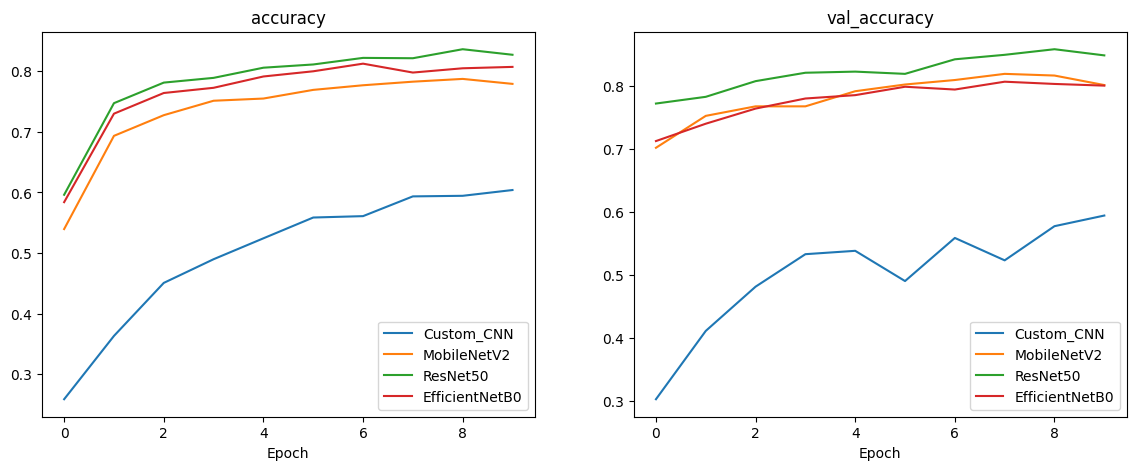

In [13]:
plt.figure(figsize=(14, 5))
for i, key in enumerate(["accuracy", "val_accuracy"]):
    plt.subplot(1, 2, i + 1)
    for name, h in histories.items():
        plt.plot(h.history[key], label=name)
    plt.title(key); plt.xlabel("Epoch"); plt.legend()
plt.show()

## 10. Hyperparameter Tuning
The best model (**ResNet50**) is tuned with a grid search:

- Learning rate: `1e-3`, `1e-4`
- Batch size: `16`, `32`
- Dropout: `0.3`, `0.5`

Each of the 8 combinations trains for up to 6 epochs, and the best one is selected using **validation accuracy** (not test), so the test set stays untouched until the end.

In [15]:
best_name = results_df.iloc[0]["Model"]
print(f"Best model: {best_name}")

tuning = []
for lr in [1e-3, 1e-4]:
    for batch in [16, 32]:
        for dropout in [0.3, 0.5]:
            print(f"lr={lr}, batch={batch}, dropout={dropout}")
            
            model, _ = train_model(best_name, lr=lr, batch=batch, dropout=dropout, epochs=6)
            acc, f1, _ = evaluate_model(model, val_ds, val_l)
            
            tuning.append({
                "lr": lr, 
                "batch": batch, 
                "dropout": dropout,
                "Val Accuracy": round(acc, 4), 
                "Val F1": round(f1, 4)
            })

tuning_df = pd.DataFrame(tuning).sort_values("Val Accuracy", ascending=False)
tuning_df

Best model: ResNet50
lr=0.001, batch=16, dropout=0.3
Epoch 1/6
329/329 ━━━━━━━━━━━━━━━━━━━━ 40s 99ms/step - accuracy: 0.6215 - loss: 0.9877 - val_accuracy: 0.7911 - val_loss: 0.5269
Epoch 2/6
329/329 ━━━━━━━━━━━━━━━━━━━━ 31s 93ms/step - accuracy: 0.7514 - loss: 0.6353 - val_accuracy: 0.8071 - val_loss: 0.4988
Epoch 3/6
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.7867 - loss: 0.5395 - val_accuracy: 0.8489 - val_loss: 0.4118
Epoch 4/6
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.8015 - loss: 0.5129 - val_accuracy: 0.8338 - val_loss: 0.4270
Epoch 5/6
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 91ms/step - accuracy: 0.8061 - loss: 0.4876 - val_accuracy: 0.8213 - val_loss: 0.4407
Epoch 6/6
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.8164 - loss: 0.4686 - val_accuracy: 0.8409 - val_loss: 0.4157
lr=0.001, batch=16, dropout=0.5
Epoch 1/6
329/329 ━━━━━━━━━━━━━━━━━━━━ 40s 100ms/step - accuracy: 0.5754 - loss: 1.1831 - val_accuracy: 0.7804 - val_loss: 0.5822
Epoch 2/6
3

,lr,batch,dropout,Val Accuracy,Val F1
0,0.0010,16,0.3,0.8489,0.8496
1,0.0010,16,0.5,0.8338,0.8354
3,0.0010,32,0.5,0.8276,0.8294
2,0.0010,32,0.3,0.8240,0.8241
4,0.0001,16,0.3,0.7627,0.7615
5,0.0001,16,0.5,0.7529,0.7518
6,0.0001,32,0.3,0.7413,0.7416
7,0.0001,32,0.5,0.7191,0.7183


### Tuning Analysis
- `lr = 0.001` is clearly better than `0.0001` (about 8–10 points). With only 6 epochs, the smaller learning rate is too slow to converge.
- A smaller batch (`16`) and lower dropout (`0.3`) gave slightly better results.
- **Best configuration:** `lr = 0.001`, `batch = 16`, `dropout = 0.3` (validation accuracy 84.9%).

## 11. Final Training
ResNet50 is retrained with the best hyperparameters for up to 15 epochs and evaluated on the test set.

In [16]:
best = tuning_df.iloc[0]
final_model, final_hist = train_model(best_name, lr=best["lr"], batch=int(best["batch"]),
                                      dropout=best["dropout"], epochs=15)
acc, f1, y_pred = evaluate_model(final_model)
print("Final Accuracy:", round(acc, 4), "| Macro F1:", round(f1, 4))

Epoch 1/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 40s 100ms/step - accuracy: 0.6183 - loss: 0.9949 - val_accuracy: 0.7778 - val_loss: 0.5477
Epoch 2/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 92ms/step - accuracy: 0.7522 - loss: 0.6379 - val_accuracy: 0.8116 - val_loss: 0.4989
Epoch 3/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.7867 - loss: 0.5493 - val_accuracy: 0.8240 - val_loss: 0.4429
Epoch 4/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.7928 - loss: 0.5066 - val_accuracy: 0.8213 - val_loss: 0.4473
Epoch 5/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 91ms/step - accuracy: 0.8168 - loss: 0.4741 - val_accuracy: 0.8373 - val_loss: 0.4189
Epoch 6/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.8156 - loss: 0.4628 - val_accuracy: 0.8293 - val_loss: 0.4166
Epoch 7/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.8278 - loss: 0.4402 - val_accuracy: 0.8391 - val_loss: 0.4376
Epoch 8/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.8160 - loss: 0.4588 -

## 12. Fine-Tuning
Fine-tuning starts from the trained model, **unfreezes the last 30 layers** of ResNet50, and trains them with a very small learning rate (`1e-5`). This lets the pretrained features adapt slightly to oral disease images without destroying them.

In [17]:
def fine_tune(model, lr=1e-5, epochs=10, batch=32):
    base_model = [l for l in model.layers if isinstance(l, keras.Model)][0]
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    train_ds = make_ds(train_p, train_l, batch=batch, train=True)
    stop = keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True)
    model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[stop])
    return model

In [18]:
acc_before, f1_before, _ = evaluate_model(final_model)
print("Before fine-tuning:", round(acc_before, 4), "| F1:", round(f1_before, 4))

final_model = fine_tune(final_model, lr=1e-5, epochs=10)

acc, f1, y_pred = evaluate_model(final_model)
print("After fine-tuning:", round(acc, 4), "| F1:", round(f1, 4))

Before fine-tuning: 0.8551 | F1: 0.8561
Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 38s 187ms/step - accuracy: 0.8480 - loss: 0.3785 - val_accuracy: 0.8720 - val_loss: 0.3488
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 172ms/step - accuracy: 0.8514 - loss: 0.3766 - val_accuracy: 0.8756 - val_loss: 0.3493
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 27s 166ms/step - accuracy: 0.8512 - loss: 0.3656 - val_accuracy: 0.8773 - val_loss: 0.3484
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 168ms/step - accuracy: 0.8512 - loss: 0.3601 - val_accuracy: 0.8773 - val_loss: 0.3472
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 170ms/step - accuracy: 0.8539 - loss: 0.3531 - val_accuracy: 0.8791 - val_loss: 0.3469
Epoch 6/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 168ms/step - accuracy: 0.8543 - loss: 0.3627 - val_accuracy: 0.8756 - val_loss: 0.3458
Epoch 7/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s 168ms/step - accuracy: 0.8581 - loss: 0.3582 - val_accuracy: 0.8773 - val_loss: 0.3460
Epoch 8/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 28s

### Fine-Tuning Results

| Stage | Test Accuracy | Test Macro F1 |
|---|---|---|
| ResNet50, default settings | 0.8507 | 0.8517 |
| After hyperparameter tuning | 0.8551 | 0.8561 |
| **After fine-tuning** | **0.8622** | **0.8635** |

Each step improved the result a little. Fine-tuning added about +0.7 points, and the total gain over the default ResNet50 is about **+1.2 points**. The gain is modest because the model was already close to what this dataset size allows.

## 13. Confusion Matrix and Classification Report
Final evaluation of the fine-tuned model on the held-out test set (1,125 images).

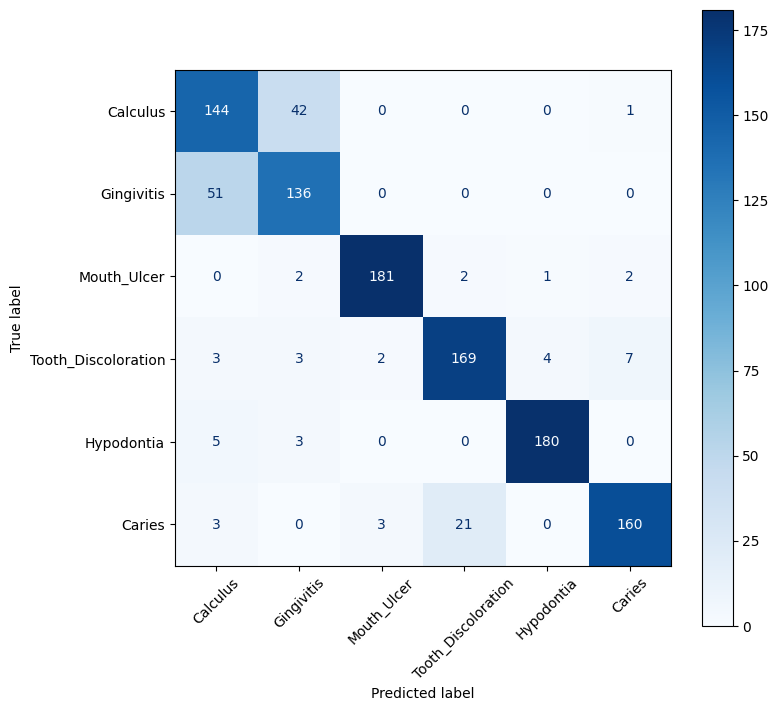

                     precision    recall  f1-score   support

           Calculus       0.70      0.77      0.73       187
         Gingivitis       0.73      0.73      0.73       187
        Mouth_Ulcer       0.97      0.96      0.97       188
Tooth_Discoloration       0.88      0.90      0.89       188
         Hypodontia       0.97      0.96      0.97       188
             Caries       0.94      0.86      0.90       187

           accuracy                           0.86      1125
          macro avg       0.87      0.86      0.86      1125
       weighted avg       0.87      0.86      0.86      1125



In [19]:
cm = confusion_matrix(test_l, y_pred)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, cmap="Blues")
plt.show()

print(classification_report(test_l, y_pred, target_names=class_names))

### Error Analysis
- **Mouth Ulcer and Hypodontia** are recognized almost perfectly (F1 = 0.97) because they look very distinctive.
- **Calculus and Gingivitis are confused with each other** (42 Calculus images predicted as Gingivitis, 51 the other way). Both appear around the gums and teeth and often occur together, so they look similar.
- **Caries is sometimes predicted as Tooth Discoloration** (21 images), because decay often shows up as a color change on the tooth.
- Without these two confusion pairs, accuracy would be close to 95%.

**Final result: 86.2% accuracy and 86.4% macro F1.**

## 14. Saving the Model
The full model and, more importantly, the **weights** are saved together with the class names. The Streamlit app rebuilds the ResNet50 architecture and loads the weights, which avoids version conflicts between Kaggle and a local machine.

In [29]:
final_model.save_weights("/kaggle/working/best.weights.h5")
with open("/kaggle/working/class_names.json", "w") as f:
    json.dump(class_names, f)
print("Saved")

Saved


## 15. Limitations and Future Work

**Limitations**
1. The Caries class has only 219 original images. The rest are augmented copies, so near-duplicates may appear in both train and test sets and can make the Caries score look better than it really is.
2. The dataset is small (1,250 images per class).
3. Calculus and Gingivitis are visually very similar and hard to separate.
4. Results vary by a few points between runs because of training randomness.
5. This is a student project and **not a medical diagnosis tool**.

**Future work**
- Split the 219 original Caries images first, then augment only the training part.
- Collect more Calculus and Gingivitis images.
- Use higher resolution and unfreeze more layers during fine-tuning.
- Add Grad-CAM heatmaps to show what the model looks at.

## Conclusion
Four models were compared on a balanced six-class dataset. **ResNet50 performed best**, and after tuning and fine-tuning it reached **86.2% test accuracy**. Pretrained models clearly beat the custom CNN, which shows how useful transfer learning is on small datasets. The model is deployed as a Streamlit app (`app.py`).